# Prova 1: Simulazione Monte Carlo

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

## Attività 1: costruzione del modello

Non negative function!
Simmetric function!
Funzione finita: True
mu(0) compatibile con Io + B: True


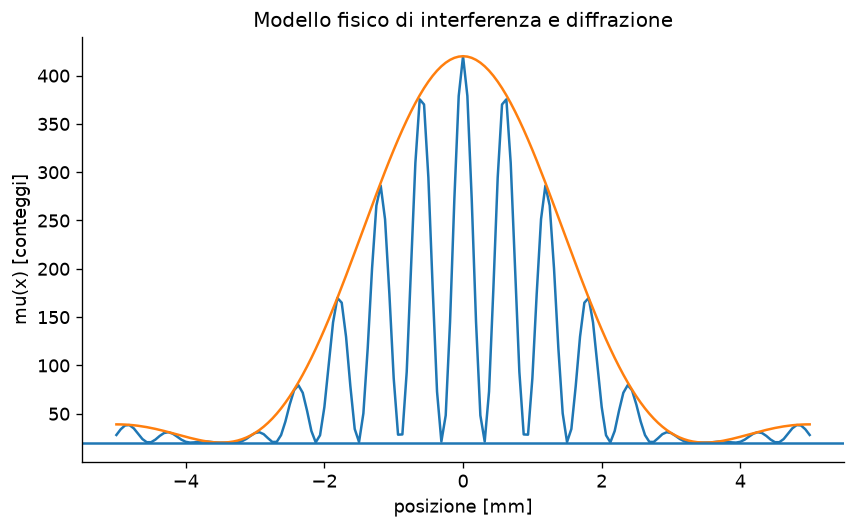

[-5.     -4.9375 -4.875  -4.8125 -4.75   -4.6875 -4.625  -4.5625 -4.5
 -4.4375 -4.375  -4.3125 -4.25   -4.1875 -4.125  -4.0625 -4.     -3.9375
 -3.875  -3.8125 -3.75   -3.6875 -3.625  -3.5625 -3.5    -3.4375 -3.375
 -3.3125 -3.25   -3.1875 -3.125  -3.0625 -3.     -2.9375 -2.875  -2.8125
 -2.75   -2.6875 -2.625  -2.5625 -2.5    -2.4375 -2.375  -2.3125 -2.25
 -2.1875 -2.125  -2.0625 -2.     -1.9375 -1.875  -1.8125 -1.75   -1.6875
 -1.625  -1.5625 -1.5    -1.4375 -1.375  -1.3125 -1.25   -1.1875 -1.125
 -1.0625 -1.     -0.9375 -0.875  -0.8125 -0.75   -0.6875 -0.625  -0.5625
 -0.5    -0.4375 -0.375  -0.3125 -0.25   -0.1875 -0.125  -0.0625  0.
  0.0625  0.125   0.1875  0.25    0.3125  0.375   0.4375  0.5     0.5625
  0.625   0.6875  0.75    0.8125  0.875   0.9375  1.      1.0625  1.125
  1.1875  1.25    1.3125  1.375   1.4375  1.5     1.5625  1.625   1.6875
  1.75    1.8125  1.875   1.9375  2.      2.0625  2.125   2.1875  2.25
  2.3125  2.375   2.4375  2.5     2.5625  2.625   2.6875  2.75   

In [ ]:
points = np.array(np.linspace(-5, +5, 161))
B=20 #fondo uniforme
Io=400 #scala del segnale
alpha=0.9 #larghezza inviluppo
delta=5.2 #frequenza spaziale del range
def E(x):
    return pow(np.sinc(alpha*x/np.pi), 2)

def C(x):
    return pow(np.cos(delta*x), 2)

def mu(x): #numero medio di conteggi atteso nel punto x
    return B + Io*E(x)*C(x)
positive = 0
symmetric=0
for i in range(161):
    if(mu(points[i])<0): positive += 1
    if(mu(points[i])!=mu(points[-1-i])): symmetric +=1

if(positive!=0): #controllo funzione positiva
    print("Negative function!")
else: 
    print("Non negative function!")

if(symmetric!=0): #controllo funzione è simmetrica 
    print("Non simmetric function!")
else: 
    print("Simmetric function!")

print("Funzione finita:", np.all(np.isfinite(mu(points)))) #controllo funzione finita
print("mu(0) compatibile con Io + B:", np.isclose(mu(0), Io + B)) #controllo compatibilità


    
plt.plot(points, mu(points))
plt.plot(points, B+Io*E(points))
plt.axhline(B)
plt.xlabel('posizione [mm]')
plt.ylabel('mu(x) [conteggi]')
plt.title('Modello fisico di interferenza e diffrazione')
plt.show()




Attività 2: 

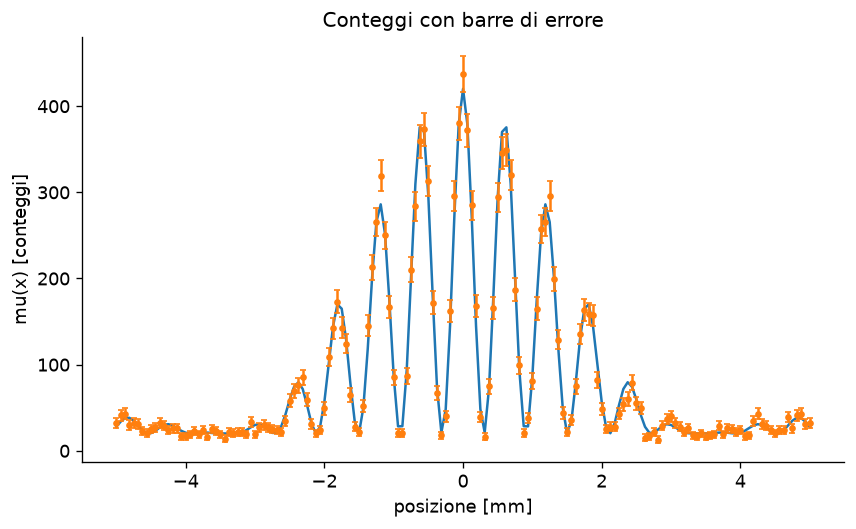

-79.45239534267876
85.81056109444035


In [3]:


rng= np.random.default_rng(seed=42)
n= np.array(rng.poisson(mu(points)))
error= np.maximum(np.sqrt(n),1.0)

plt.plot(points, mu(points))
plt.errorbar(points, n, yerr=error, fmt='o', markersize=3, capsize=2)
plt.xlabel('posizione [mm]')
plt.ylabel('mu(x) [conteggi]')
plt.title('Conteggi con barre di errore')
plt.show()


Nc=sum(n[62:100])
muc=sum(mu(points[62:100]))

print(Nc-muc)
print(np.sqrt(muc))



Attività 3

87.2752425546987
85.81056109444035


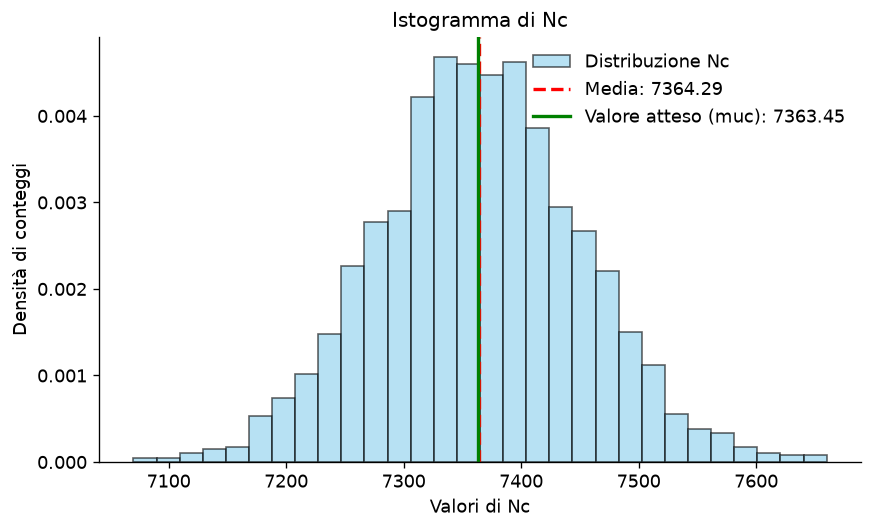

In [4]:

rng = np.random.default_rng()
Nc_arr = np.zeros(2000)  
for i in range(2000):
    Nc_arr[i] = sum(rng.poisson(mu(points[62:100])))

mean= sum(Nc_arr)/2000
dev_std= np.sqrt(sum(pow(Nc_arr-mean,2)/1999))
mean_err = dev_std/np.sqrt(2000)
scarto = (mean - muc)/muc

print(dev_std)
print(np.sqrt(muc))


plt.hist(Nc_arr, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Distribuzione Nc')
plt.axvline(mean, color='red', linestyle='dashed', linewidth=2, label=f'Media: {mean:.2f}')
plt.axvline(muc, color='green', linestyle='solid', linewidth=2, label=f'Valore atteso (muc): {muc:.2f}')
plt.xlabel('Valori di Nc')
plt.ylabel('Densità di conteggi')
plt.title('Istogramma di Nc')
plt.legend()
plt.show() 
    


# Prova 2: fit e diagnostica

stampa parametri attività 1 su un file e inizia qui leggendoli dal file di testo

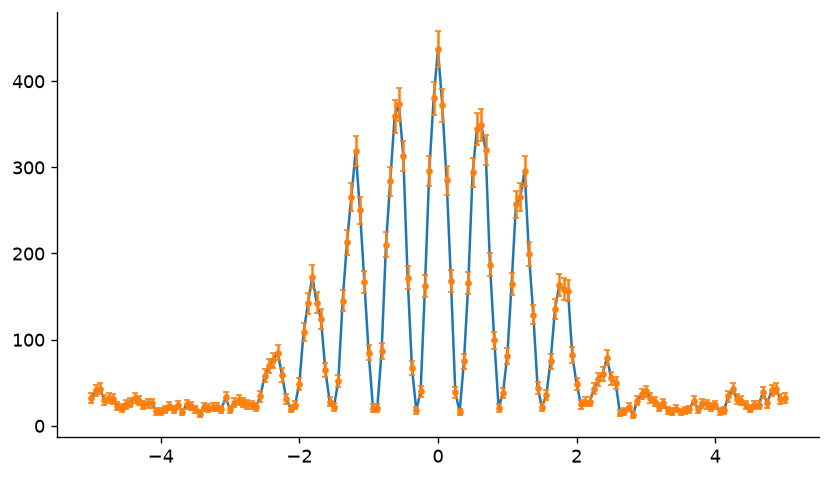

In [13]:
matrice_dati=np.column_stack((points, n, np.sqrt(n)))
np.savetxt('data.txt', matrice_dati, delimiter='\t', header='x\ty\tsigma_y')
dati=np.genfromtxt("data.txt", delimiter='\t', names=True)
x=dati["x"]
y=dati["y"]
sigma_y=dati["sigma_y"]


plt.plot(x,y)
plt.errorbar(x,y,yerr=sigma_y,fmt='o', markersize=3, capsize=2)
plt.show()